# CsI–SiPM：QDC尾部与F202离散度的剩余差异

2026-11-01，承接[独立Geant4统计复现](codex_0001_csi_independent_mc_statistics.ipynb)。上一轮新增25.6万个母衰变后，Am平均时间95%分位宽度比从0.872变为0.980；但晚段扩展谱的QDC外侧宽度仍偏大，F202的事件间SD比为Co1.232、Am1.201。

本轮固定已有参数、事件、原Q和统计目标，追查这两类残差的结构。**新增Geant4母事件、原生读出重放、实验事件均为0；没有拟合或替换响应，没有剔除尾部事件，没有改变正式PID。**
先提交上一阶段：`d481527`，英文题目 `Validate CsI PID tails with independent Geant4 statistics`。本笔记属于该提交后的继续分析。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/qdc_fluctuation_20261101'
def read(p):return json.loads(Path(p).read_text())
def fmt(x,n=3):return '不可估计' if x is None else f'{x:.{n}f}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+']'
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');e=read(OUT/'analysis.json');decision=read(OUT/'decision.json')
variants=p['variants'];labels={'frozen':'原冻结','inherited_CV_fit':'RC+原谱','spectrum_CV_fit':'RC+扩展谱'}
print('方案冻结提交:',p['checkpoint_commit'])
print('输入哈希数:',len(p['inputs_sha256']),'本轮独立母事件:',p['new_independent_mothers'])
display(Markdown(decision['conclusion_zh']))

方案冻结提交: d481527e3539394ce21537ae635b0119935c9031
输入哈希数: 251 本轮独立母事件: 0


完成固定事件的F方差分解、QDC尾部关联、逐Q箱和采集段检查；未调参数、未删事件，也未增加独立模拟或实测样本。具体点值和条件区间见全部表格。

## 1. F的精确定义与分解

对每条原ADC，使用与上一轮相同的25/51/101样点中心滑动均值残差，对应50/102/202 ns。前触发窗200个样点、信号窗1000个样点，边界仍为原 `ceil(t10−300)` 和 `ceil(t10+250)`；两窗的方差均使用 `ddof=1`。

\[
F=\frac{V_{\rm post}-V_{\rm pre}}{\mu}=P+B+D,
\quad P=\frac{V_{\rm post}}{\mu_0},\quad B=-\frac{V_{\rm pre}}{\mu_0},
\quad D=(V_{\rm post}-V_{\rm pre})\left(\frac1\mu-\frac1{\mu_0}\right).
\]

其中μ是该事件信号窗平均幅度；μ₀只用同一原Q箱的**对折实验**、原Q两半目标权重求得，两个源及采集段分别定义。μ₀不是每事件幅度匹配，也没有用于修改模拟波形。

事件间方差保留完整3×3协方差。每项的贡献定义为 `Cov(该项,F)`，三项严格相加得到 `Var(F)`，可以为负；不把它们解释成三种独立物理噪声方差。固定分母的 `P+B` 只是诊断量，原F和PID保持不变。


|晚段run|固定响应|指标|MC/实测比|条件95%区间|
|---|---|---|---|---|
|3|原冻结|F202_SD_ratio|1.251|[1.187, 1.345]|
|3|原冻结|F202_fixed_denominator_SD_ratio|1.225|[1.157, 1.323]|
|3|原冻结|F202_within_cell_SD_ratio|1.291|[1.221, 1.438]|
|3|原冻结|width95_QDC_ratio|1.045|[0.983, 1.153]|
|3|RC+原谱|F202_SD_ratio|1.224|[1.161, 1.317]|
|3|RC+原谱|F202_fixed_denominator_SD_ratio|1.205|[1.138, 1.302]|
|3|RC+原谱|F202_within_cell_SD_ratio|1.264|[1.196, 1.409]|
|3|RC+原谱|width95_QDC_ratio|1.047|[0.982, 1.152]|
|3|RC+扩展谱|F202_SD_ratio|1.232|[1.168, 1.326]|
|3|RC+扩展谱|F202_fixed_denominator_SD_ratio|1.212|[1.145, 1.310]|
|3|RC+扩展谱|F202_within_cell_SD_ratio|1.272|[1.205, 1.417]|
|3|RC+扩展谱|width95_QDC_ratio|1.072|[1.011, 1.177]|
|12|原冻结|F202_SD_ratio|1.083|[1.012, 1.185]|
|12|原冻结|F202_fixed_denominator_SD_ratio|1.012|[0.943, 1.107]|
|12|原冻结|F202_within_cell_SD_ratio|1.101|[1.032, 1.228]|
|12|原冻结|width95_QDC_ratio|1.023|[0.925, 1.137]|
|12|RC+原谱|F202_SD_ratio|1.205|[1.127, 1.317]|
|12|RC+原谱|F202_fixed_denominator_SD_ratio|1.116|[1.037, 1.230]|
|12|RC+原谱|F202_within_cell_SD_ratio|1.224|[1.148, 1.372]|
|12|RC+原谱|width95_QDC_ratio|1.051|[0.959, 1.180]|
|12|RC+扩展谱|F202_SD_ratio|1.201|[1.122, 1.312]|
|12|RC+扩展谱|F202_fixed_denominator_SD_ratio|1.107|[1.029, 1.219]|
|12|RC+扩展谱|F202_within_cell_SD_ratio|1.222|[1.147, 1.370]|
|12|RC+扩展谱|width95_QDC_ratio|1.090|[1.002, 1.227]|

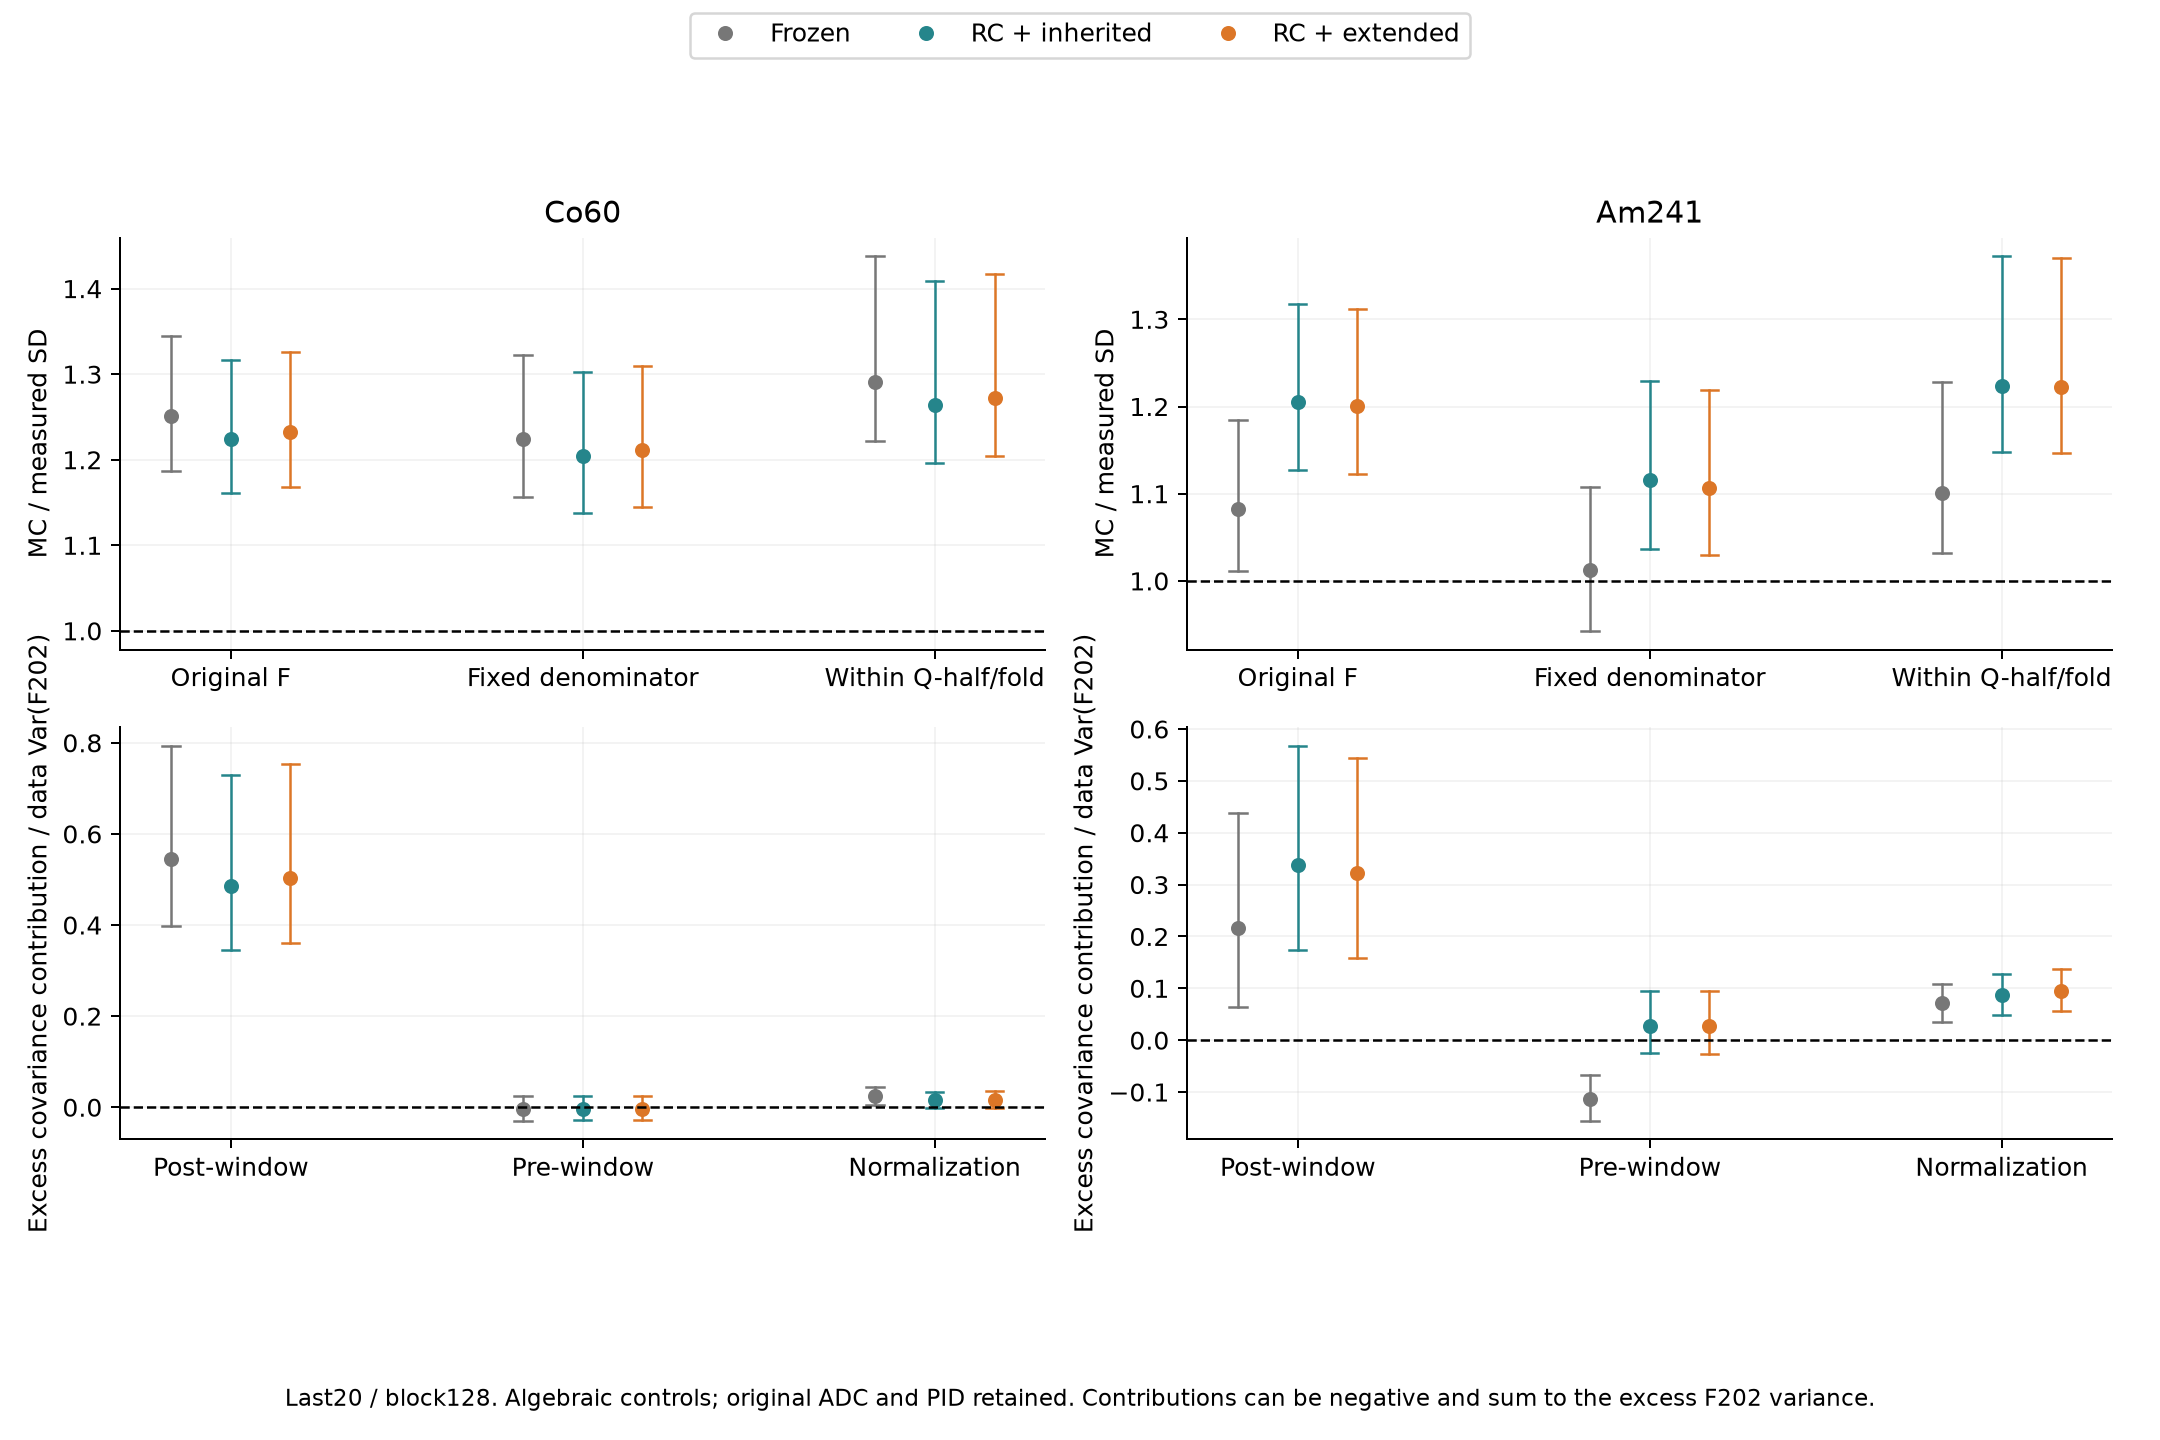

In [2]:
names=['F202_SD_ratio','F202_fixed_denominator_SD_ratio','F202_within_cell_SD_ratio','width95_QDC_ratio']
rows=[]
for run in [3,12]:
    for v in variants:
        r=e['groups'][f'run{run}_last20']['128']['variants'][v]
        for n in names:rows.append([run,labels[v],n,fmt(r['point'][n]),ci(r['CI95'][n])])
display(Markdown(table(['晚段run','固定响应','指标','MC/实测比','条件95%区间'],rows)))
display(Image(filename=str(OUT/'figures/fluctuation_term_controls.png')))

In [3]:
rows=[]
for run in [3,12]:
    r=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']
    for term in ['post_window','pre_window','normalization']:
        n=f'F202_{term}_excess_over_data_variance'
        rows.append([run,term,fmt(r['point'][n]),ci(r['CI95'][n])])
    print('run',run,'三项总和:',sum(r['point'][f'F202_{t}_excess_over_data_variance'] for t in ['post_window','pre_window','normalization']),
          '直接方差超额/实测方差:',r['point']['F202_SD_ratio']**2-1)
display(Markdown(table(['晚段run','协方差贡献差/实测F202方差','点值','条件95%区间'],rows)))

run 3 三项总和: 0.5176241690281506 直接方差超额/实测方差: 0.5176241690281511
run 12 三项总和: 0.44240483649709395 直接方差超额/实测方差: 0.4424048364970945


|晚段run|协方差贡献差/实测F202方差|点值|条件95%区间|
|---|---|---|---|
|3|post_window|0.504|[0.360, 0.753]|
|3|pre_window|-0.003|[-0.027, 0.024]|
|3|normalization|0.016|[-0.002, 0.036]|
|12|post_window|0.322|[0.159, 0.545]|
|12|pre_window|0.027|[-0.026, 0.095]|
|12|normalization|0.094|[0.056, 0.137]|

## 2. Q条件与响应折的结构

所有方差延续上一轮“原Q箱内方差、再箱间等权”的定义，不混入不同Q箱均值之差。进一步将箱内协方差精确分成：Q两半之间、每半箱内响应折之间、半箱/折内部三项，保留原目标质量和全部事件。

折间均值项含有限样本均值误差，不等于真实电路状态漂移；这里只检查能否用这种分组结构解释当前差异。Co保留6箱，Am保留前3箱，逐箱的样本数和有效样本量另列，不根据结果删除电荷箱。


|run|Q箱|实测数|实测ESS|MC数|MC ESS|QDC95%比|区间|F202 SD比|区间|
|---|---|---|---|---|---|---|---|---|---|
|3|0|28|28.0|362|334.2|0.871|[0.813, 1.240]|1.222|[1.011, 1.664]|
|3|1|54|53.4|375|362.1|1.082|[0.819, 1.465]|1.243|[1.052, 1.649]|
|3|2|106|105.1|362|353.3|1.241|[1.078, 1.464]|1.178|[0.997, 1.442]|
|3|3|209|203.0|337|319.1|1.167|[1.007, 1.334]|1.228|[1.093, 1.386]|
|3|4|274|274.0|364|363.6|1.131|[0.933, 1.336]|1.156|[1.043, 1.304]|
|3|5|150|150.0|375|337.2|1.074|[0.900, 1.329]|1.382|[1.201, 1.616]|
|12|0|154|153.9|462|443.2|1.207|[1.041, 1.457]|1.149|[0.985, 1.342]|
|12|1|99|96.8|618|601.7|1.057|[0.950, 1.241]|1.165|[1.018, 1.377]|
|12|2|63|63.0|326|313.4|0.997|[0.835, 1.231]|1.332|[1.176, 1.593]|

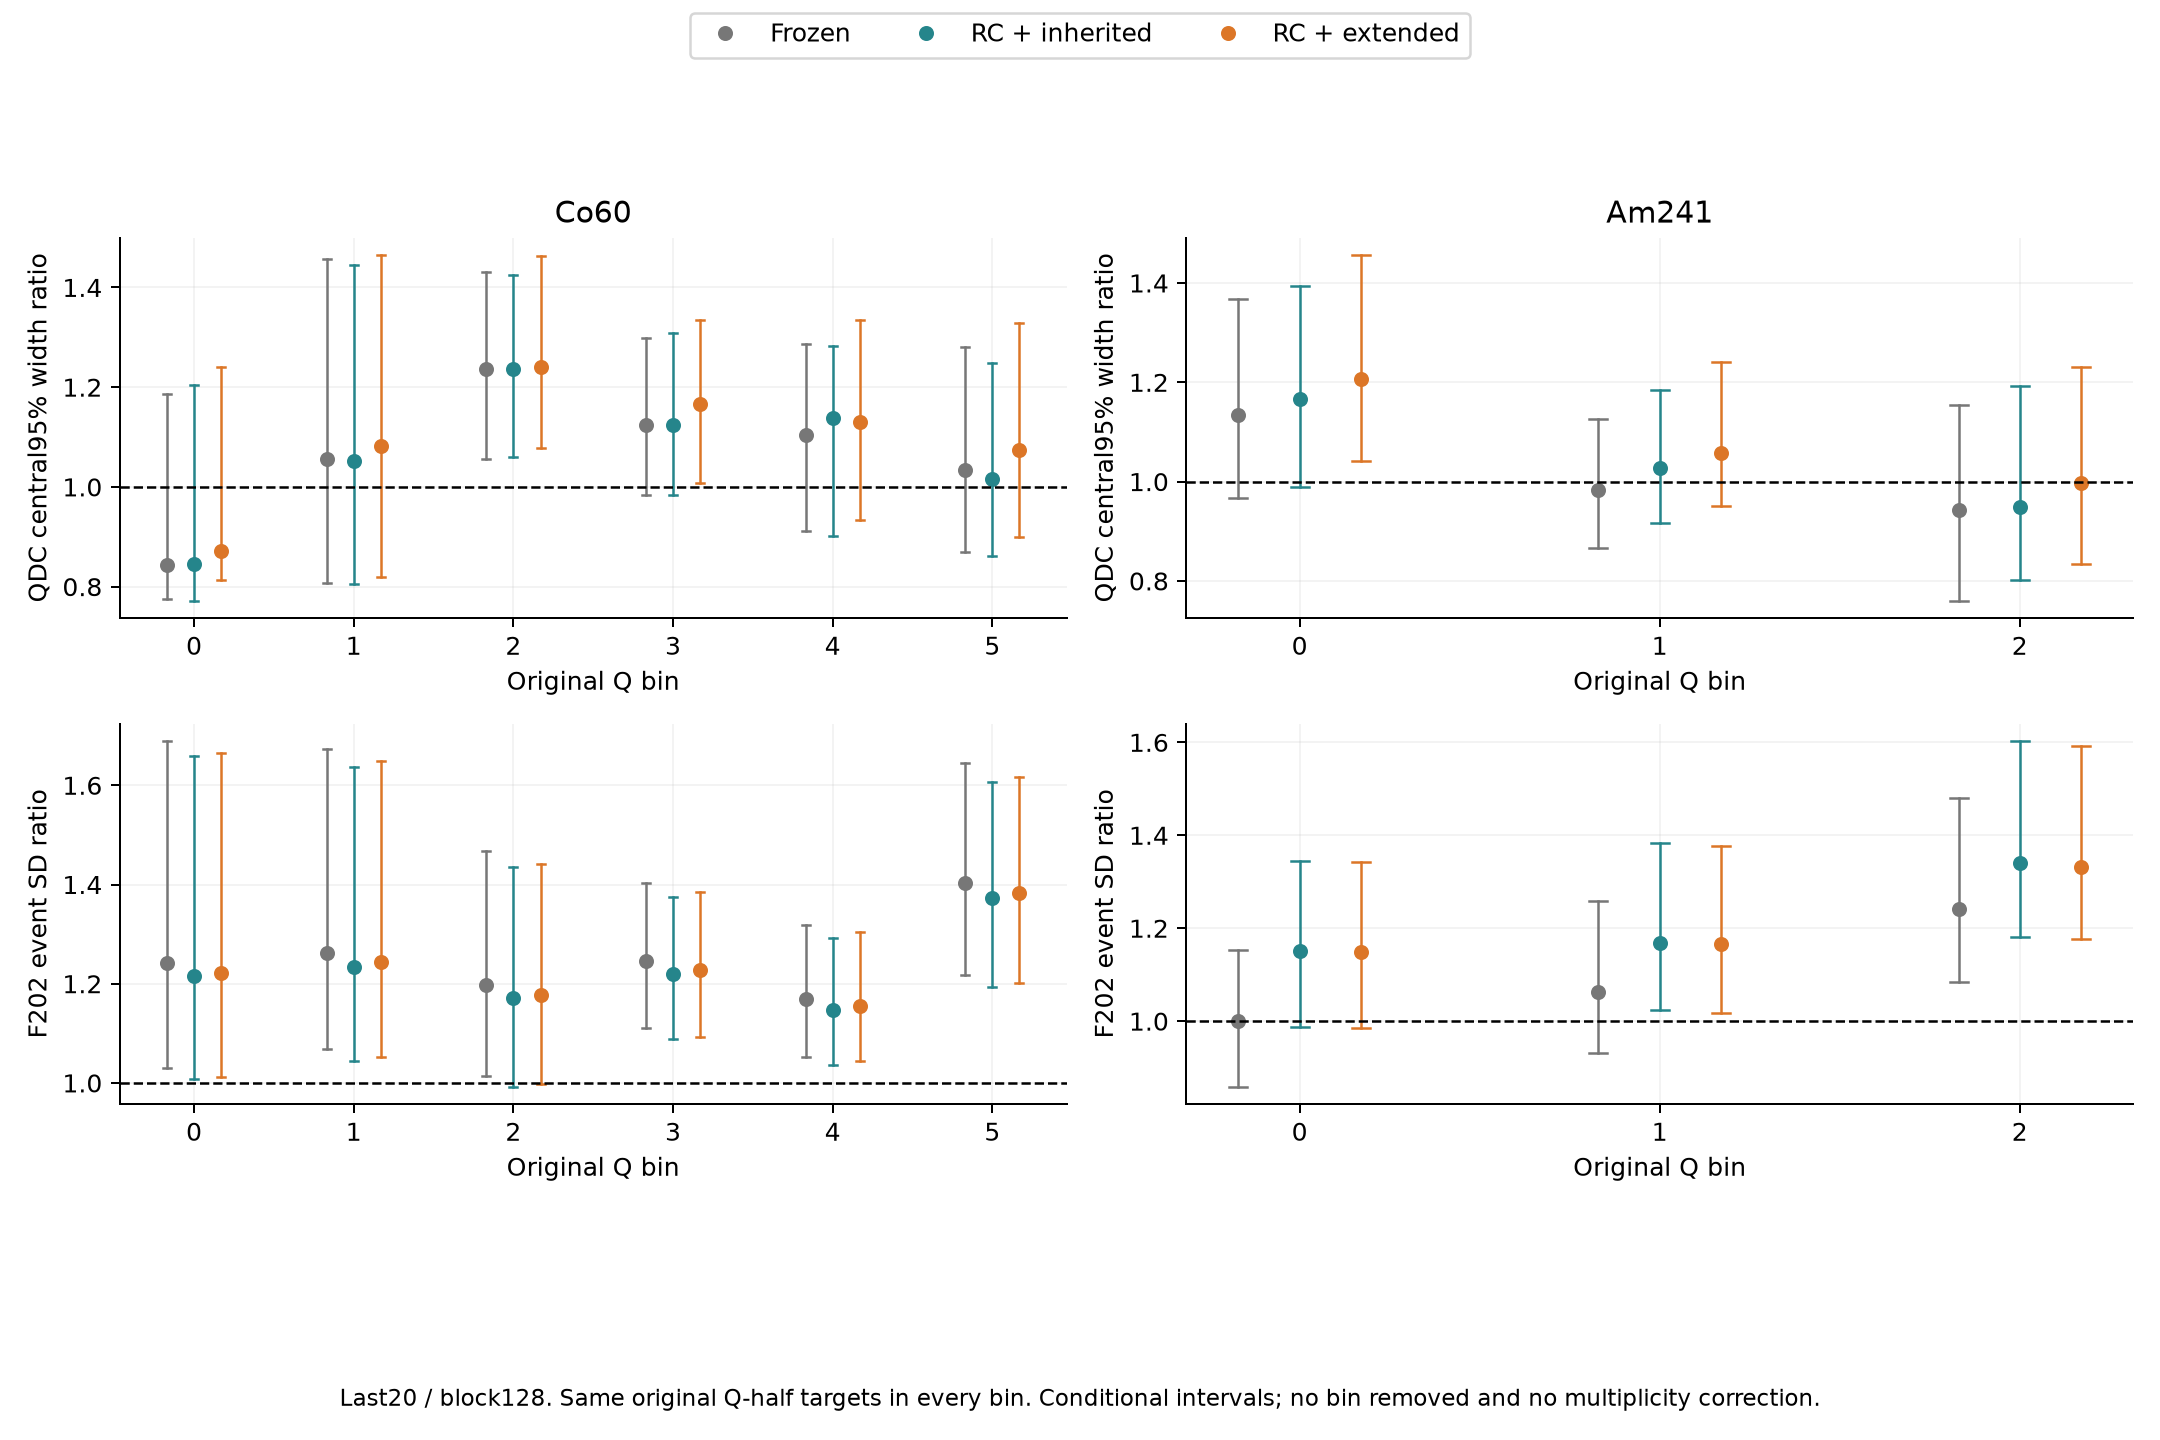

In [4]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128'];r=g['variants']['spectrum_CV_fit']
    for i,b in enumerate(r['per_Q']):
        d=g['data']['per_Q'][i];m=r['summary']['per_Q'][i];x=r['per_Q'][b]
        rows.append([run,b,d['events'],fmt(d['ESS'],1),m['events'],fmt(m['ESS'],1),
                     fmt(x['point']['width95_QDC_ratio']),ci(x['CI95']['width95_QDC_ratio']),
                     fmt(x['point']['F202_SD_ratio']),ci(x['CI95']['F202_SD_ratio'])])
display(Markdown(table(['run','Q箱','实测数','实测ESS','MC数','MC ESS','QDC95%比','区间','F202 SD比','区间'],rows)))
display(Image(filename=str(OUT/'figures/fluctuation_by_charge.png')))

## 3. QDC尾部与F202外侧是否重合

QDC尾部继续使用旧对折实验的稳健标准化 `abs(z)>2`。F202外侧定义为新对折实验5%/95%分位之外，同时报告下侧和上侧；阈值不从MC选择，也不在本轮bootstrap中重新拟合。
5%/95%是训练折的分位，评价折的外侧质量不必等于10%；原计数、加权质量和统计区间应一起阅读。

按“均不在尾部、仅QDC、仅F202、两者同时”四类分配全部事件，统计权重质量和各自对完整箱内方差的贡献。F、QDC及幅度归一化共享ADC样点，尾部重合、相关系数或共同方差不能单独识别因果；这些标签不是坏事件、堆积或粒子类型分类。


|run|队列|四类原事件数|四类加权质量/%|F下侧/%|F上侧/%|
|---|---|---|---|---|---|
|3|实测|628 / 60 / 128 / 5|73.74 / 6.50 / 19.21 / 0.55|11.60|8.16|
|3|原冻结|1500 / 178 / 445 / 52|68.96 / 8.24 / 20.37 / 2.44|12.13|10.67|
|3|RC+原谱|1525 / 161 / 448 / 41|70.20 / 7.47 / 20.42 / 1.90|13.12|9.20|
|3|RC+扩展谱|1514 / 166 / 447 / 48|69.65 / 7.70 / 20.40 / 2.24|13.02|9.62|
|12|实测|260 / 11 / 44 / 1|80.46 / 4.52 / 14.49 / 0.54|8.11|6.91|
|12|原冻结|1124 / 57 / 215 / 10|78.90 / 4.83 / 15.48 / 0.79|5.66|10.61|
|12|RC+原谱|1043 / 60 / 288 / 15|73.13 / 4.60 / 21.06 / 1.21|10.09|12.19|
|12|RC+扩展谱|1038 / 69 / 281 / 18|72.53 / 5.33 / 20.62 / 1.52|10.29|11.85|

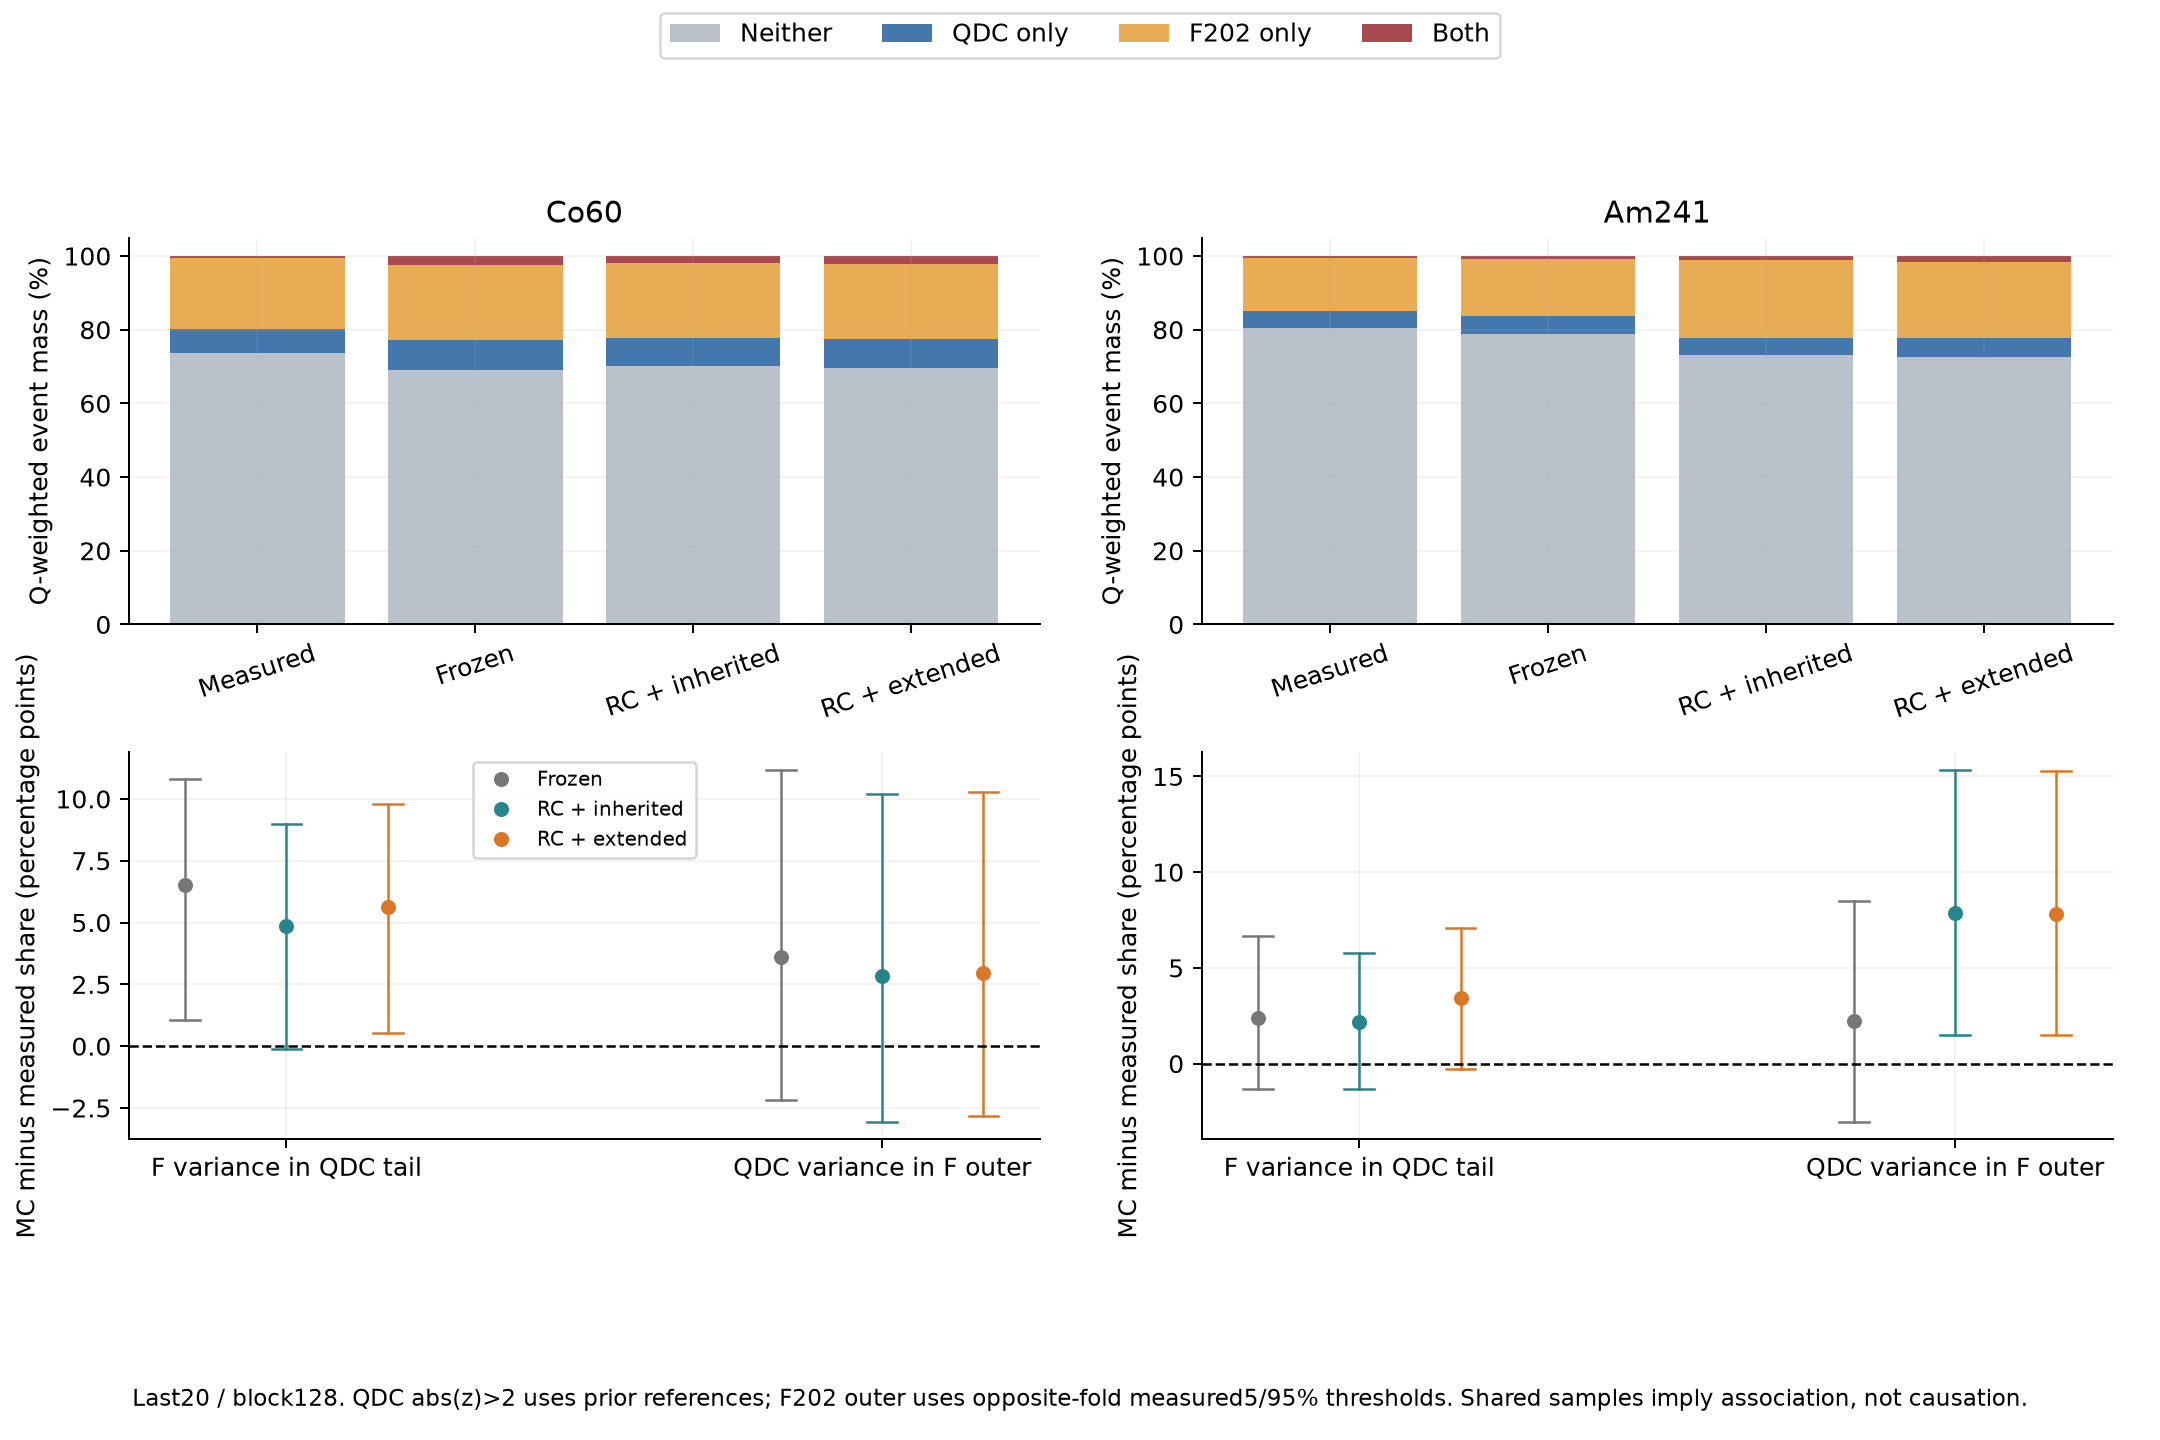

In [5]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']
    for label,s in [('实测',g['data'])]+[(labels[v],g['variants'][v]['summary']) for v in variants]:
        rows.append([run,label,' / '.join(str(x) for x in s['category_counts']),
                     ' / '.join(fmt(100*x,2) for x in s['category_mass']),
                     fmt(100*s['F_lower_mass'],2),fmt(100*s['F_upper_mass'],2)])
display(Markdown(table(['run','队列','四类原事件数','四类加权质量/%','F下侧/%','F上侧/%'],rows)))
display(Image(filename=str(OUT/'figures/fluctuation_tail_overlap.png')))

## 4. 模拟内部：原生信号、附加残差与交叉项

对MC保存的原生信号S和 `ADC−原基线−S` 得到的附加残差N，使用同一个线性局部滤波与原窗边界。每个窗的方差满足 `V(S+N)=V(S)+V(N)+2Cov(S,N)`；前后窗作差并除原μ，得到三个逐事件F分量，再计算它们对事件间F方差的协方差贡献。

原生信号包含光子、雪崩及响应涨落；附加残差合并了电子噪声、经验信号相关残差和ADC量化。交叉项不能删掉。这一模型潜变量分解不对实验可观测，不能用“附加残差贡献大”直接宣称已经测得某一种实验噪声。


|run|固定响应|尺度/ns|信号贡献/实测方差|附加残差贡献|交叉贡献|总MC/实测方差|
|---|---|---|---|---|---|---|
|3|原冻结|50|-0.000|0.986|0.011|0.997|
|3|原冻结|102|0.009|1.283|0.105|1.397|
|3|原冻结|202|0.097|1.109|0.359|1.565|
|3|RC+原谱|50|-0.000|0.950|0.010|0.960|
|3|RC+原谱|102|0.008|1.235|0.099|1.342|
|3|RC+原谱|202|0.090|1.069|0.339|1.499|
|3|RC+扩展谱|50|-0.000|0.943|0.010|0.954|
|3|RC+扩展谱|102|0.008|1.231|0.098|1.338|
|3|RC+扩展谱|202|0.091|1.083|0.344|1.518|
|12|原冻结|50|0.001|0.828|0.010|0.840|
|12|原冻结|102|0.006|0.912|0.061|0.979|
|12|原冻结|202|0.020|0.970|0.183|1.173|
|12|RC+原谱|50|0.001|0.887|0.014|0.902|
|12|RC+原谱|102|0.006|1.032|0.081|1.120|
|12|RC+原谱|202|0.022|1.194|0.235|1.452|
|12|RC+扩展谱|50|0.002|0.871|0.013|0.886|
|12|RC+扩展谱|102|0.008|1.014|0.079|1.101|
|12|RC+扩展谱|202|0.024|1.185|0.233|1.442|

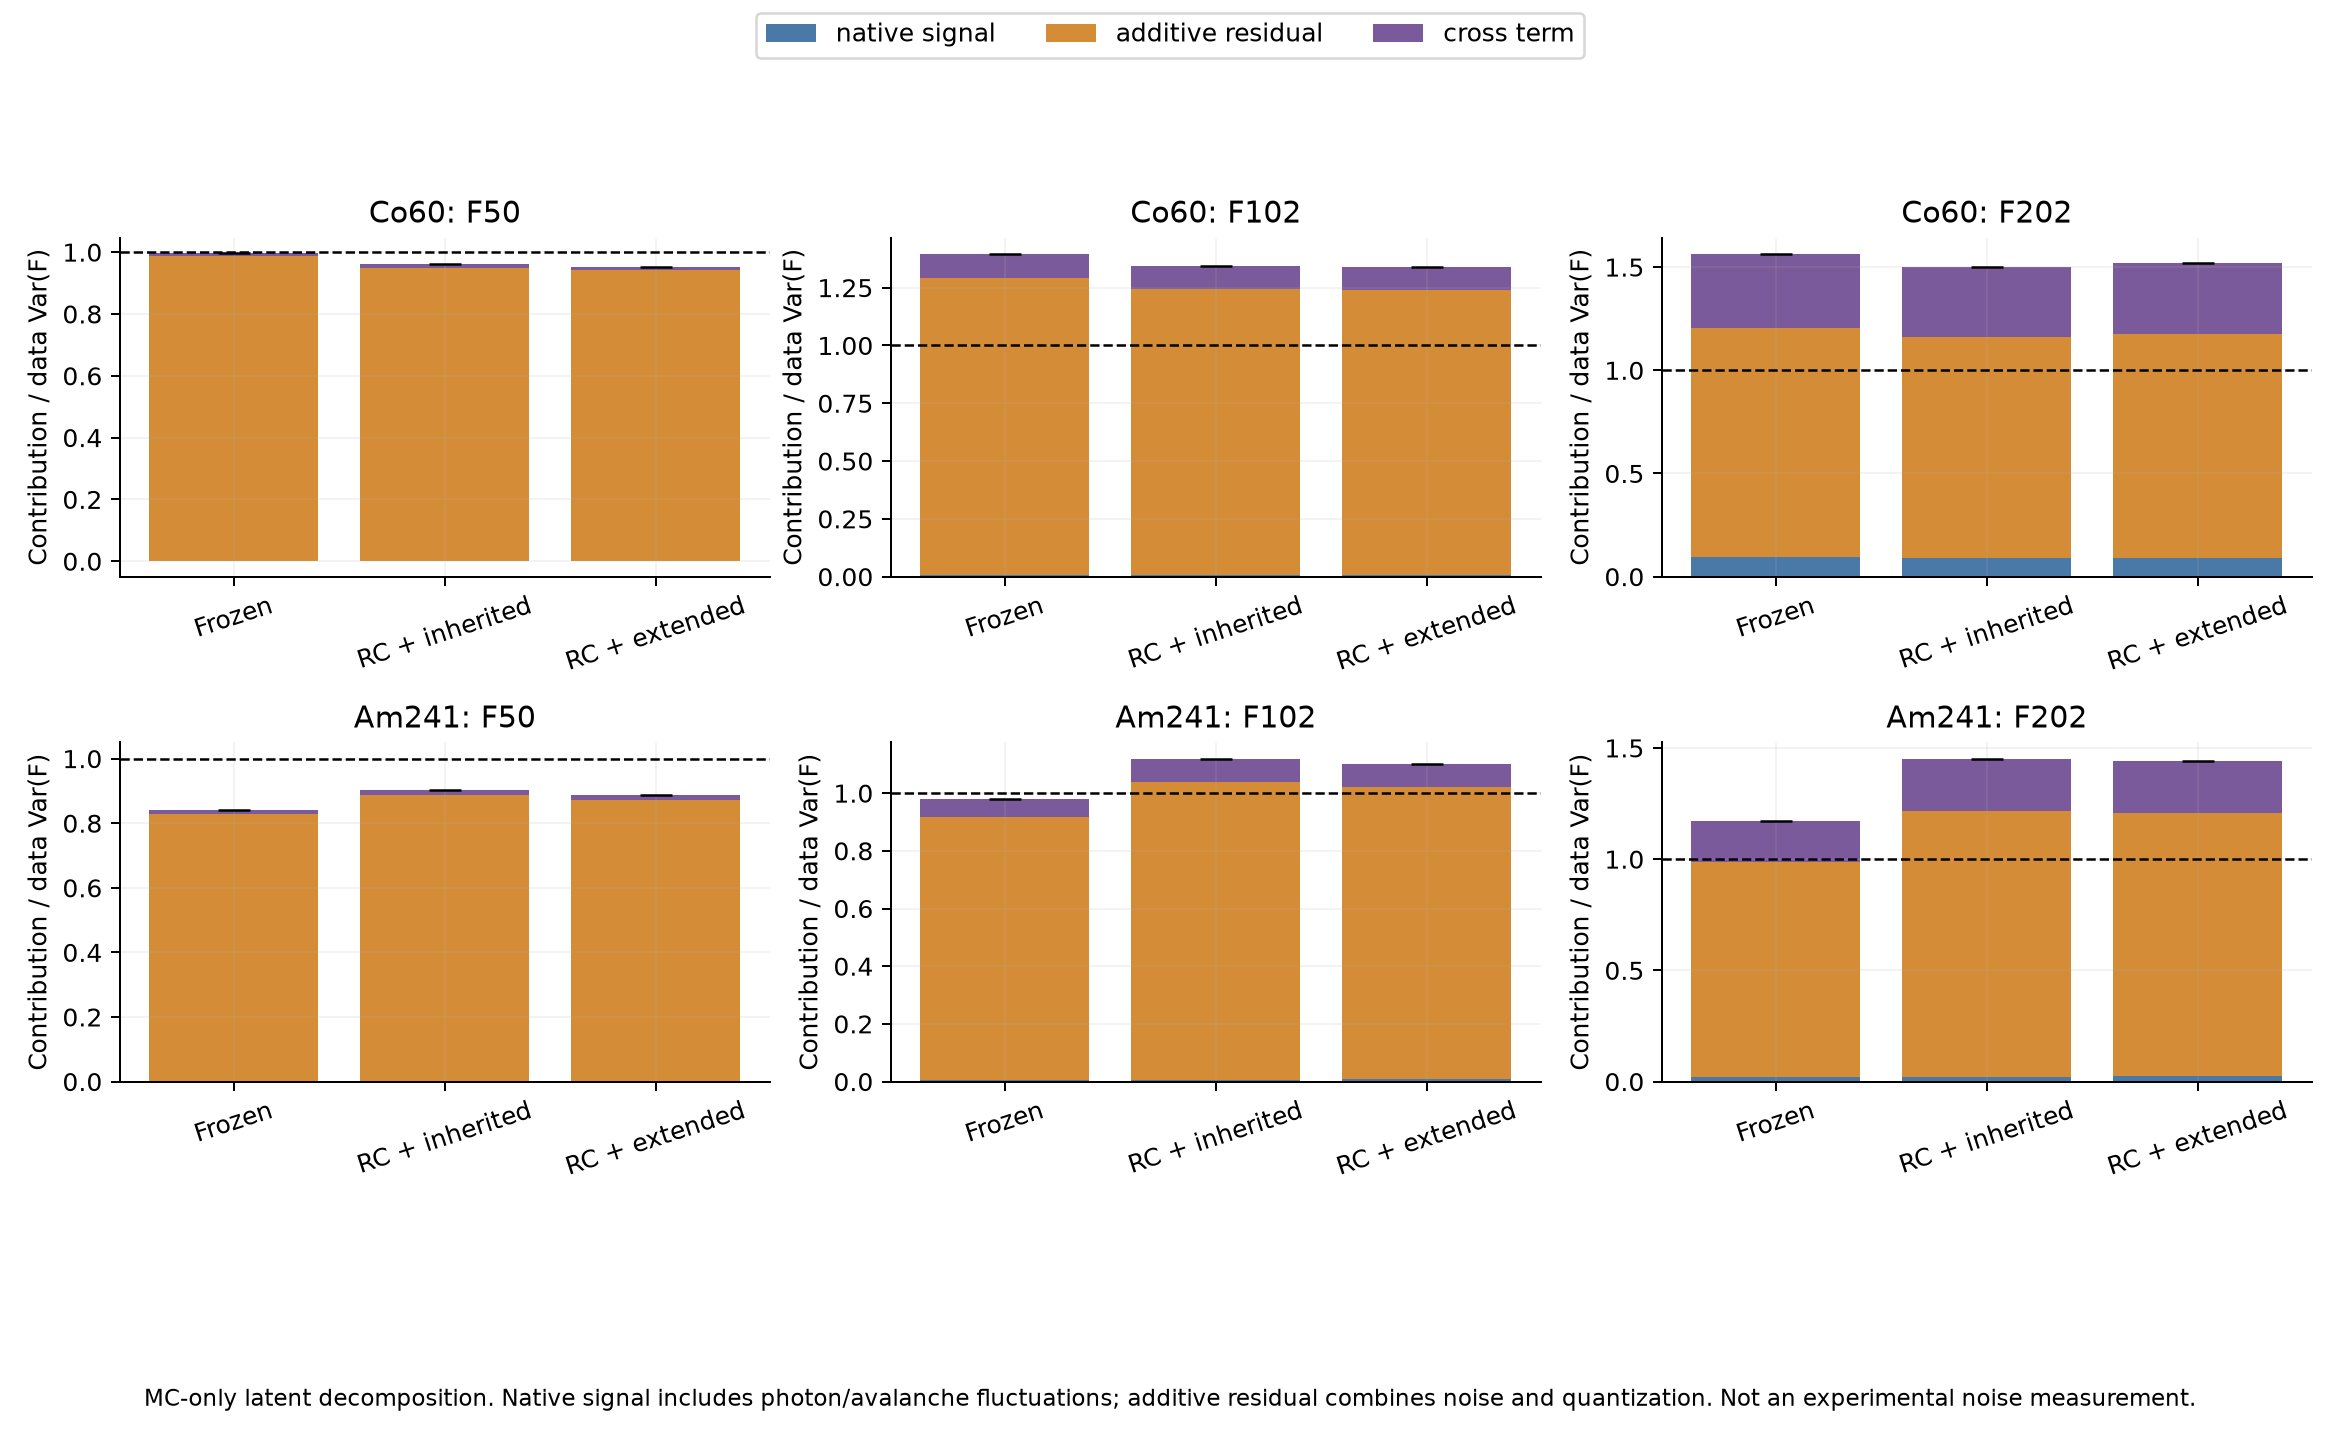

In [6]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128'];dv=np.diag(g['data']['cov'])[1:]
    for v in variants:
        c=np.asarray(g['variants'][v]['summary']['native_terms_cov'])
        for i,w in enumerate([50,102,202]):
            x=c[i].sum(1)/dv[i]
            rows.append([run,labels[v],w,*[fmt(z) for z in x],fmt(x.sum())])
display(Markdown(table(['run','固定响应','尺度/ns','信号贡献/实测方差','附加残差贡献','交叉贡献','总MC/实测方差'],rows)))
display(Image(filename=str(OUT/'figures/fluctuation_native_parts.png')))

## 5. 采集段、块长与统计口径核验

报告前60%、中间20%、最后20%以及块64/128。全部实验和本轮MC已用于诊断，不能称盲验证。

沿用上一轮相同的512次实验原索引块抽样、四批独立母事件的分层完整母事件抽样，保留原随机流中旧母事件抽样的消耗顺序，使配对样本完全相同。QDC的50%/95%宽度、三个F均值及三个F事件SD，**共8项既有指标在所有36种条件/响应下、每次抽样均须复现父记录**。新派生量区间固定全部响应、参考和权重，不包含拟合/模型系统误差，也没有多重比较校正或等效性检验。


|组|块长|F202 SD比|区间|半箱/折内SD比|QDC95%比|父抽样逐次闭合|
|---|---|---|---|---|---|---|
|run3_first60|64|1.114|[1.051, 1.182]|1.124|1.067|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run3_first60|128|1.115|[1.060, 1.175]|1.115|1.071|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run3_middle20|64|1.093|[1.047, 1.189]|1.137|1.048|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run3_middle20|128|1.099|[1.057, 1.200]|1.120|1.038|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run3_last20|64|1.226|[1.152, 1.337]|1.236|1.088|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run3_last20|128|1.232|[1.168, 1.326]|1.272|1.072|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_first60|64|1.027|[0.965, 1.096]|1.030|1.026|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_first60|128|0.988|[0.924, 1.058]|0.987|1.038|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_middle20|64|1.107|[1.007, 1.219]|1.117|1.094|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_middle20|128|1.074|[0.974, 1.171]|1.092|1.098|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_last20|64|1.181|[1.103, 1.282]|1.197|1.096|{'metrics': 8, 'draws': 512, 'variants': 3}|
|run12_last20|128|1.201|[1.122, 1.312]|1.222|1.090|{'metrics': 8, 'draws': 512, 'variants': 3}|

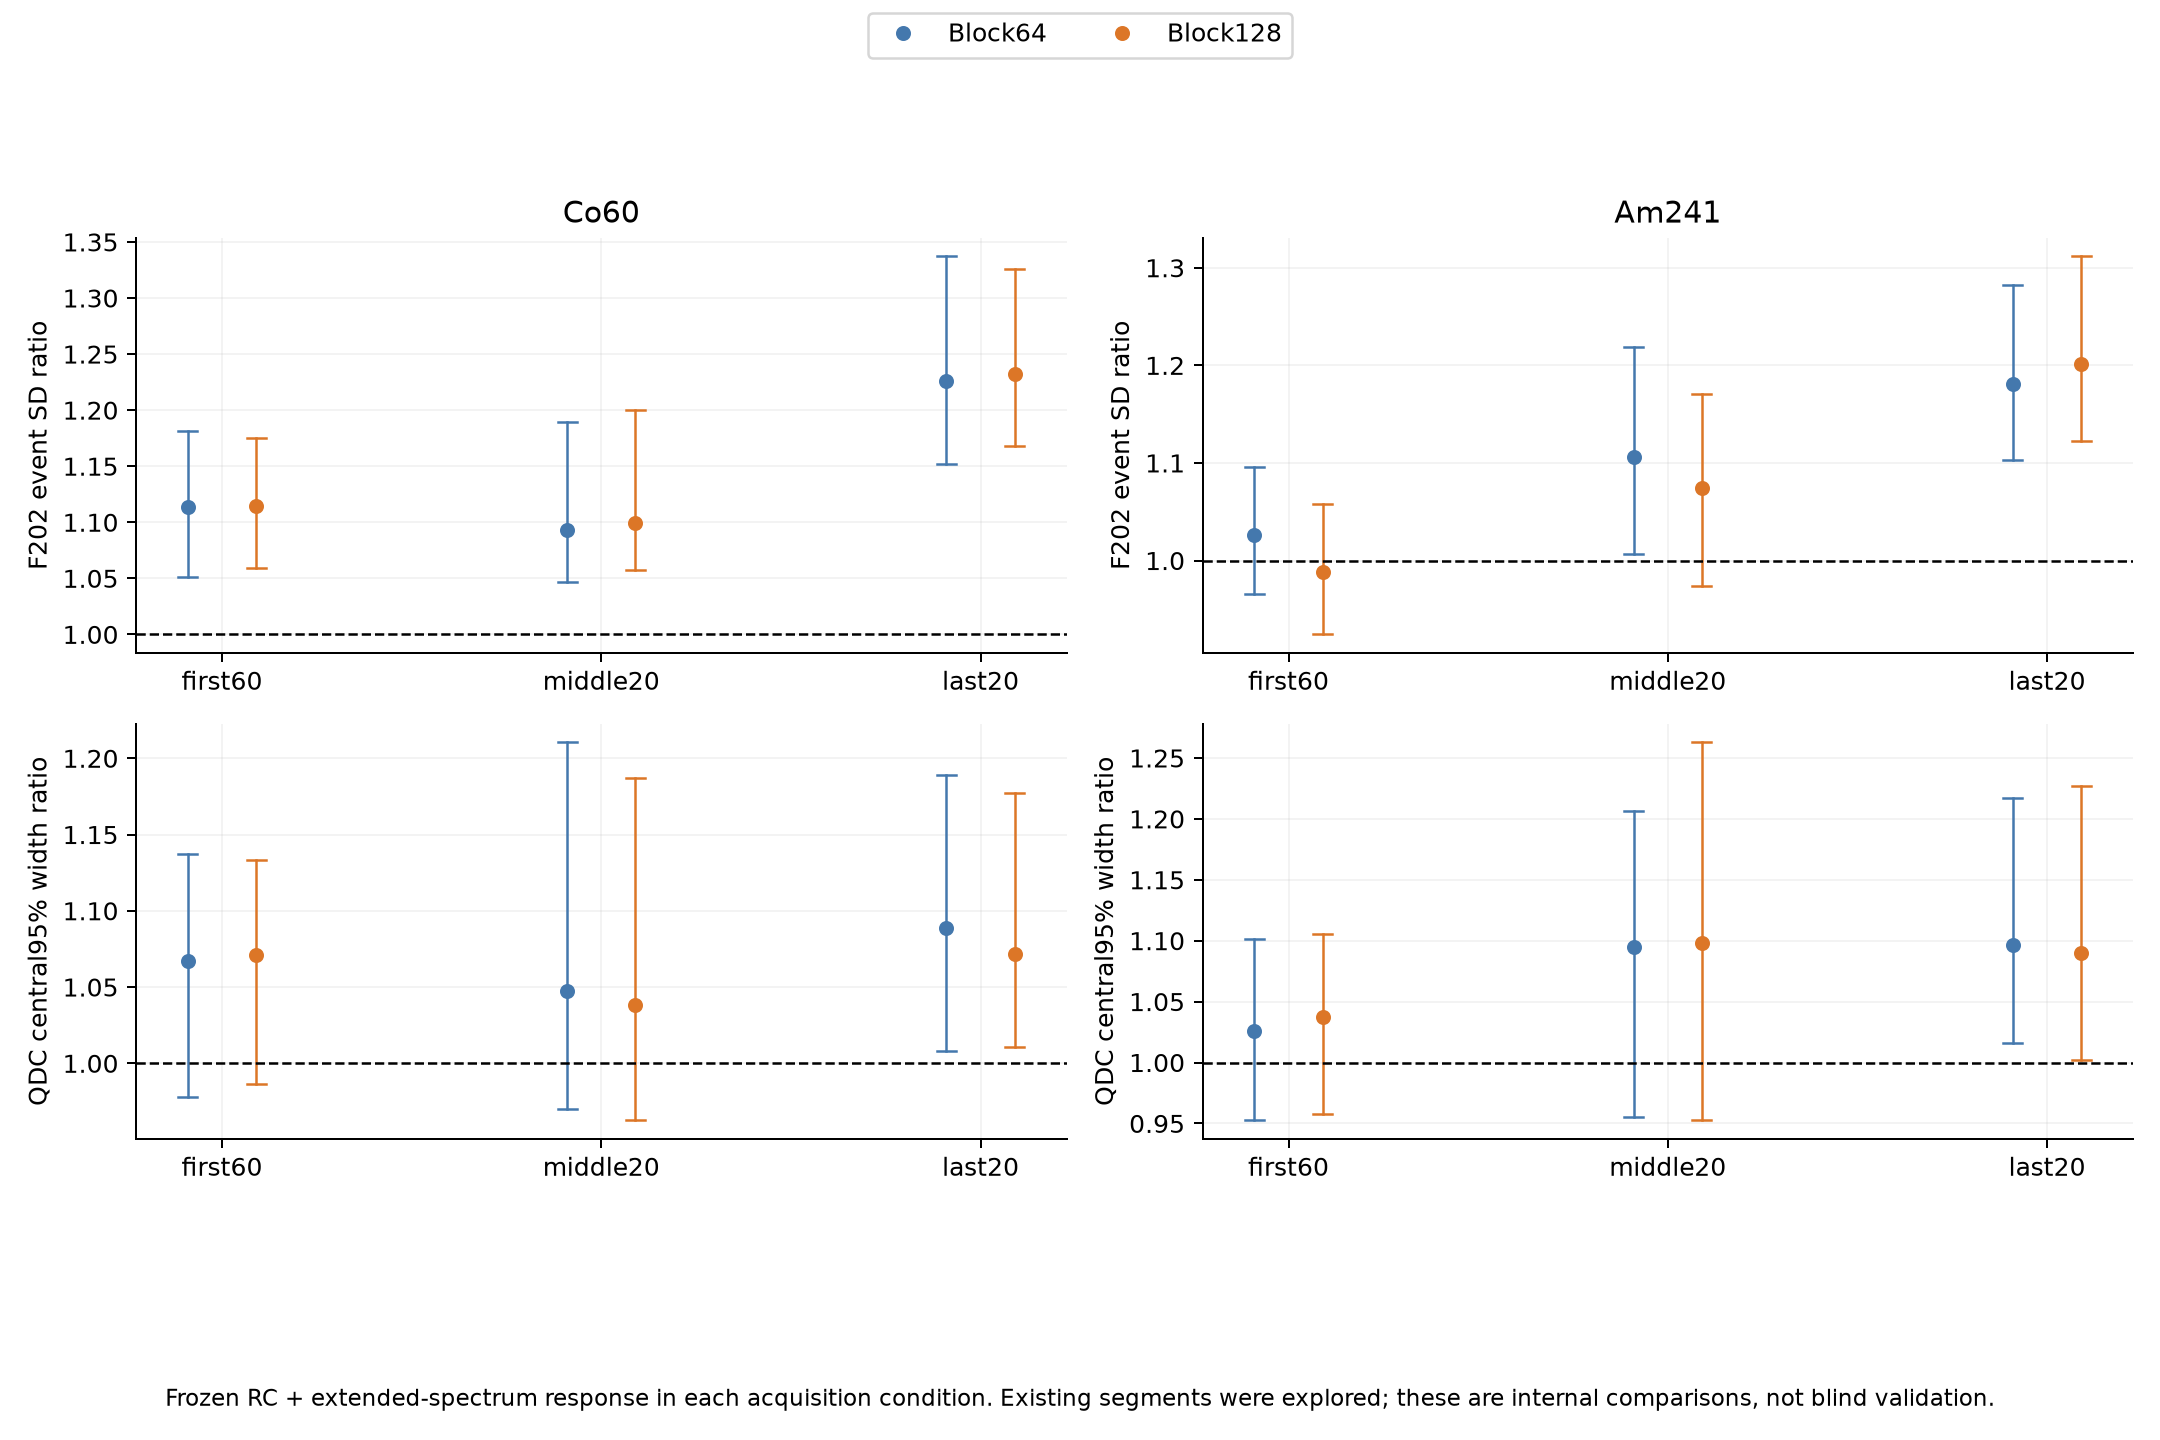

In [7]:
rows=[]
for key,blocks in e['groups'].items():
    for B,g in blocks.items():
        r=g['variants']['spectrum_CV_fit']
        rows.append([key,B,fmt(r['point']['F202_SD_ratio']),ci(r['CI95']['F202_SD_ratio']),
                     fmt(r['point']['F202_within_cell_SD_ratio']),fmt(r['point']['width95_QDC_ratio']),
                     g['parent_metric_draw_closure']])
display(Markdown(table(['组','块长','F202 SD比','区间','半箱/折内SD比','QDC95%比','父抽样逐次闭合'],rows)))
display(Image(filename=str(OUT/'figures/fluctuation_segment_controls.png')))

## 6. 判断与可复现记录


In [8]:
for finding in decision['findings_zh']:display(Markdown(finding))
display(Markdown(decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))
print('结果目录:',OUT)
print('计算：analyze_qdc_fluctuation.py prepare → analyze --workers 2')
print('报告：report_qdc_fluctuation.py；笔记：jupyter/codex_0001_build_qdc_fluctuation_notebook.py')
print('核验/封存：verify_qdc_fluctuation.py [--archive]')

结果目录: /media/sf_works/SiPM/simulation/results/qdc_fluctuation_20261101
计算：analyze_qdc_fluctuation.py prepare → analyze --workers 2
报告：report_qdc_fluctuation.py；笔记：jupyter/codex_0001_build_qdc_fluctuation_notebook.py
核验/封存：verify_qdc_fluctuation.py [--archive]


Co60晚段块128：F202事件SD比1.232，固定分母诊断为1.212，只看Q半箱/响应折内部的SD比为1.272。这两种计算不是对原波形或PID的校正。

Co60的F202方差超额/实验方差为0.518；信号窗、前触发窗、归一化三项的协方差贡献差分别为0.504/-0.003/0.016，严格相加得到该超额。贡献可以为负，不能解释为三种独立噪声强度。

Co60的QDC尾部承载实验/模拟F202方差5.9%/11.6%；F202外侧承载实验/模拟QDC方差19.7%/22.6%。边界只由对折实验定义，所有事件保留；关联不是因果解释。

Co60模型内部F202事件方差的信号/附加残差/交叉协方差贡献为6.0%/71.4%/22.6%。附加残差合并多种模型项；这些比例不是实验噪声测量。

Am241晚段块128：F202事件SD比1.201，固定分母诊断为1.107，只看Q半箱/响应折内部的SD比为1.222。这两种计算不是对原波形或PID的校正。

... (6 outputs left out)

边界：F、QDC和归一化量使用同一波形，相关、尾部重合和带符号协方差贡献不能单独识别噪声因果。

边界：5%/95%是训练折分位，评价折外侧质量不必等于10%；尤其联合尾部实测事件很少，需保留原计数与条件区间。

边界：MC信号/残差分解仅限已保存的模型输出，无法把相同潜变量标签直接赋给实验；Am实验主带不作为纯α真值。

边界：Q半箱与折间均值项含有限样本均值噪声；去除该统计项的诊断不等于已校正真实漂移。

`protocol.json`在新派生结果出现前冻结方案和输入哈希；`references/`保存对折参考；`arrays/`保存原ID、原Q及逐事件分解；`evaluation/`保存逐条件点值和全部配对区间；`analysis.json`汇总结果。

`comparison_table.csv`、`per_Q_table.csv`、`batch_table.csv`分别保存36行总体、162行逐Q箱和144行逐种子批点值，所有固定响应均保留。`verification.json`、`record.json`和源码快照记录核验及封存。共享文献库保持只读，本轮没有联网、下载或新实验。
